

# Table of Contents

**Phase 1: Data Preparation and Metrics Definition**
- 1.1 Preprocessing and Data Cleaning
- 1.2 Definition of Key Metrics
- 1.3 Network Construction and Representation

**Phase 2: Outbreak Detection and Analysis**  
- 2.1 Community Exploration and Structure Analysis	
- 2.2 Outbreak Identification and Characterization

**Phase 3: Propagation and Diffusion Analysis**  
- 3.1 Cascade Tracing and Flow Dynamics
- 3.2 Immunity and Containment Effects

**Phase 4: Lifecycle and Evolution Study**  
- 4.1 Detection of Cycles and Key Events
- 4.2 Evolutionary Tracking Over Time

**Phase 5: Validation and Synthesis of Results**  
- 5.1 Cross-Validation and Robustness Checks
- 5.2 Final Interpretation and Conclusions


### **Install Requirements**

In [1]:
%pip install -r pip_requirements.txt

  Using cached datasets-2.18.0-py3-none-any.whl.metadata (20 kB)
  Using cached transformers-4.39.3-py3-none-any.whl.metadata (134 kB)
  Using cached wandb-0.17.2-py3-none-win_amd64.whl.metadata (10 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached pyarrow_hotfix-0.7-py3-none-any.whl.metadata (3.6 kB)
  Using cached dill-0.3.8-py3-none-any.whl.metadata (10 kB)
  Using cached fsspec-2024.2.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached tokenizers-0.15.2.tar.gz (320 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'
Note: you may need to restart the kernel to use 

  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [22 lines of output]
      Checking for Rust toolchain....
      Rust not found, installing into a temporary directory
      Python reports SOABI: cp313-win_amd64
      Computed rustc target triple: x86_64-pc-windows-msvc
      Installation directory: C:\Users\aksel\AppData\Local\puccinialin\puccinialin\Cache
      Rustup already downloaded
      Installing rust to C:\Users\aksel\AppData\Local\puccinialin\puccinialin\Cache\rustup
      warn: It looks like you have an existing rustup settings file at:
      warn: C:\Users\aksel\.rustup\settings.toml
      warn: Rustup will install the default toolchain as specified in the settings file,
      warn: instead of the one inferred from the default host triple.
      info: profile set to 'minimal'
      info: default host triple is x86_64-pc-windows-msvc
      warn: Updating existing toolchain, profile choice will 

### **Imports**

In [2]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from statsmodels.stats import diagnostic
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *

# Project pipeline




---
# Phase 1: Data Preparation

## 1.1 Preprocessing & Cleaning


### Data Quality Checks, Unification & Standardization

We import and preprocess data through the following steps:

1. Import TSV files and expand PROPERTIES column into 86 features
2. Merge together both title and body datasets in a unified dataset, with `TYPE` to retain information of source.
3. Standardize subreddit names (lowercase, trim whitespace)
4. Convert timestamps to datetime and chronologically reorder the combined dataset (temporal integrity was altered by merging)
5. Format embeddings datasets (one subreddit per row, one column for each embedding dimension)
6. Check data quality (missing values, timestamp parsing)
7. Check for duplicates and document dataset overlap

The steps are performed using functions defined in `init_data.py`.

In [3]:
# Data quality and duplicates check
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [4]:
# DataFrame after STEP 1 
interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body


## 1.2 Definition of Key Metrics



**Aggregation Levels:**
All metrics computed at multiple scopes:
- Subreddit level (aggregated over time windows)
- Subreddit-pair level (source → target relationships)
- Community cluster level (aggregated within detected communities)

### 1.2.1 Core Toxicity Metric

Our first fundamental preliminary step is to calculate a reliable and accurate metric of toxicity of each subreddit's post.

By toxicity, we refer to patterns of communication or behavior that create a hostile, disrespectful, or harmful environment for participants. This can include insults, harassment, hate speech, excessive negativity, or attempts to provoke conflict. Toxicity reduces constructive discussion, discourages participation, and can damage the overall health and cohesion of the community.

The majority of these characteristics are captured by some of the 86 properties that are already includeded in our dataset. Let's understand what they actually represent.

**Properties 1 to 18** capture surface-level linguistic and structures of the text. They measure the basic composition and readability of a message, including its length, complexity, and word or sentence structure. They include metrics such as character and word counts, fractions of different character types (letters, digits, punctuation, etc.), sentence length averages, and readability scores. Together, they provide a quantitative snapshot of how the text is written rather than what it expresses.

**Properties 19 to 21** represent sentiment analysis metrics, derived using the VADER (Valence Aware Dictionary and sEntiment Reasoner) model. They aim to measure the emotional polarity of the text. It includes the Positive Sentiment, Negative Sentiment and Compound Sentiment. These features reflect the emotional valence of the language used.

**Properties 22 to 86** are purely lexicon-based ratios, derived using a text analyis tool called Linguistic Inquiry and Word Count (LIWC). Each LIWC represent the proportion of words in a text that belong to a certain lexicon: LIWC_X = (nb words in lexicon X) / (total nb words). While useful to see the presence of a certain vocubulary in a post, they remain purely lexical and doesn't treat emotion or sentiment in any way.

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_SCORE</code>: continuous metric that measures the toxicity intensity in a subreddit post, using the 86 existing properties 
</div>

(Function also implemented in `compute_toxicity_score.py` in `utils` module.)

**Properties that are interesting for capturing toxicity**

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | `Number of UPPERCASE words`, `Readability index`... 

However, above all these textual properties, we also consider true **negativity** of a post to be a **necessary** component for it to be toxic.

**The problem: none of the 86 properties provides a reliable measure of emotional negativity in a post.** 

While the VADER scores seemed promising (optimized for social media texts and posts), they mainly work like a LIWC score and calculate emotion of the **language** that was used (like an advanced lexical repertory of words that are conventionally considered negative or harmful on social platforms).

This cannot be considered an accurate measure of negativity in our context. For example, some shortfalls of lexical metrics include:

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like “grenade” or “headshots.” These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).

**Good news: `LINK_SENTIMENT` solves this problem.**

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

We want to explore what are the properties that play a determinant role in negativity. To do so, we compare the normalized property means between positive and negative links (normalized because some properties have different scales and centers). Look which are the most significantly different for positive VS negative links.

,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,FRACTION_OF_WHITE_SPACES,FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC,NUMBER_OF_WORDS,NUMBER_OF_UNIQUE_WORDS,NUMBER_OF_LONG_WORDS_AT_LEAST_6_CHARACTERS,...,LIWC_ACHIEV,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER
min,7.0,7.0,0.016340,0.00000,0.000505,0.000126,0.001277,1.0,1.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.000000,0.0,0.0
median,107.0,94.0,0.777778,0.00000,0.083333,0.146341,0.062554,18.0,17.0,4.0,...,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.000000,0.0,0.0
max,41239.0,39369.0,0.994208,0.85077,0.993485,0.880000,0.917808,7600.0,2693.0,1978.0,...,0.555556,0.9,0.555556,0.916667,0.75,0.6,0.769231,0.967742,0.6,0.6


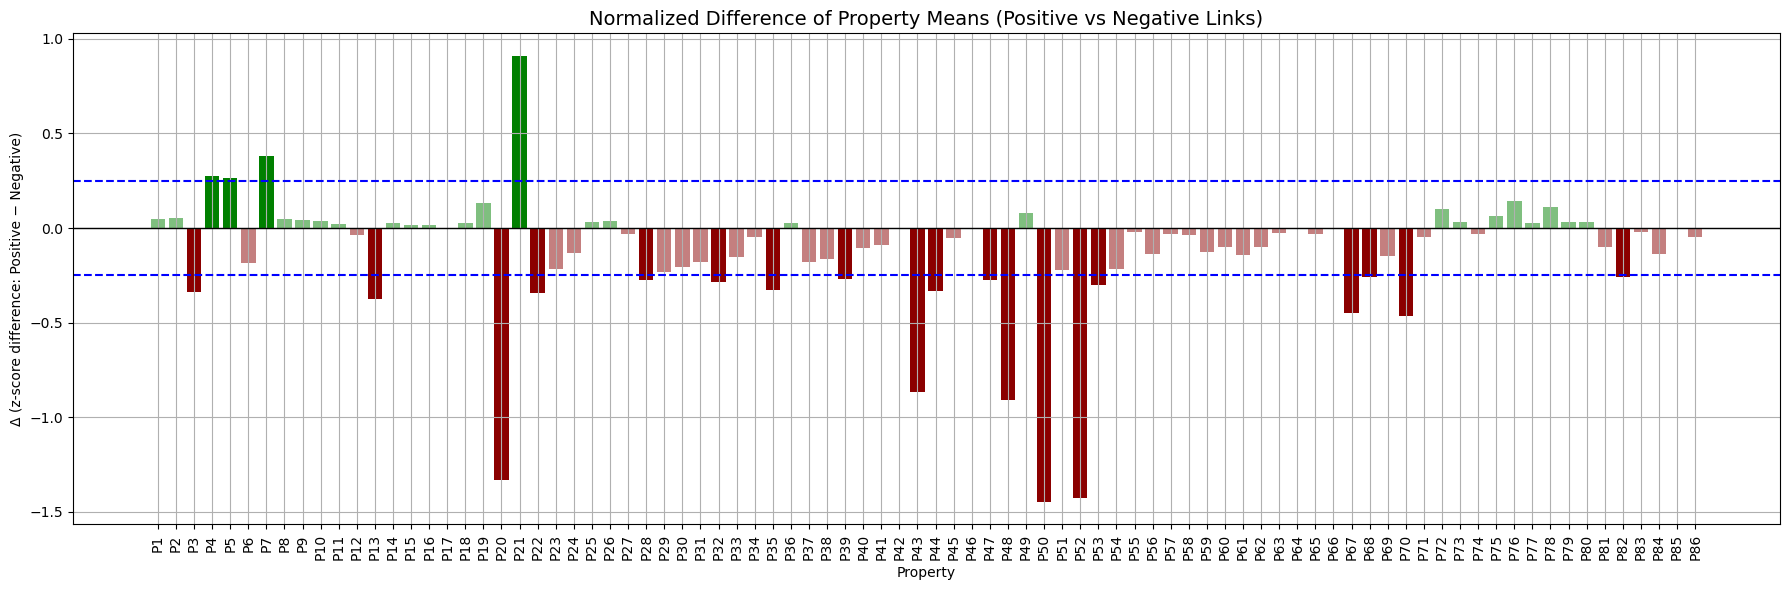

Found 4 properties higher for positive links (zΔ > 0.25):
- (z_diff = 0.273) 	 FRACTION_OF_DIGITS
- (z_diff = 0.262) 	 FRACTION_OF_UPPERCASE_CHARACTERS
- (z_diff = 0.382) 	 FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC
- (z_diff = 0.911) 	 COMPOUND_SENTIMENT_CALCULATED_BY_VADER

 Found 19 properties higher for negative links (zΔ < -0.25):
- (z_diff = -0.34) 	 FRACTION_OF_ALPHABETICAL_CHARACTERS
- (z_diff = -0.375) 	 FRACTION_OF_STOPWORDS
- (z_diff = -1.33) 	 NEGATIVE_SENTIMENT_CALCULATED_BY_VADER
- (z_diff = -0.346) 	 LIWC_FUNCT
- (z_diff = -0.272) 	 LIWC_SHEHE
- (z_diff = -0.287) 	 LIWC_VERBS
- (z_diff = -0.326) 	 LIWC_PRESENT
- (z_diff = -0.27) 	 LIWC_CONJ
- (z_diff = -0.867) 	 LIWC_SWEAR
- (z_diff = -0.33) 	 LIWC_SOCIAL
- (z_diff = -0.273) 	 LIWC_HUMANS
- (z_diff = -0.909) 	 LIWC_AFFECT
- (z_diff = -1.448) 	 LIWC_NEGEMO
- (z_diff = -1.425) 	 LIWC_ANGER
- (z_diff = -0.302) 	 LIWC_SAD
- (z_diff = -0.451) 	 LIWC_BIO
- (z_diff = -0.259) 	 LIWC_BODY
- (z_diff = -0.465

In [5]:
threshold = 0.25
avg_z_diffs = evaluate_props_norm_diffs(interactions_df, threshold)

Combining our qualitative choice of what defines toxicity with the will to mainly use properties that prove to appear in negative hyperlinks only, below is our final choice of the toxicity_metric. Note that all these properties represent ratios (values between 0 and 1).

Our `TOXICITY_SCORE` metric will be a combination of all these properties.

For this initial exploration, we define the continuous `TOXICITY_SCORE` as a **weighted average** of the retained properties. The current weights are derived from intuitive coefficients based on established literature in toxicity and destructive discourse, prioritizing a fast, interpretable metric that reflects our working definition of toxicity. While this approach is **simple and effective for preliminary analysis**, in the future **we plan to explore more advanced options**, such as performing Logistic Regression on a small, manually labeled subset of the data to derive statistically optimized weights, for example. It can also turn out better to do more than a simple linear combination and we might use interaction terms and non-linear functions of property scores.

Mathematically, `TOXICITY_SCORE` will therefore range from -1 to 1.

In [6]:
interactions_df["LINK_SENTIMENT_ADJUST"] = (1 - (interactions_df["LINK_SENTIMENT"] + 1)/2)/4

tox_props = pd.DataFrame([
    [-3, "FRACTION_OF_DIGITS"],
    [0, "LINK_SENTIMENT_ADJUST"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [0, "LIWC_AFFECT"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum() 
#display(tox_props)

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE,LINK_SENTIMENT_ADJUST,TOXICITY_SCORE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title,0.0,0.008514
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title,0.0,0.000000
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body,0.0,0.019065
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title,0.0,0.021591
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body,0.0,0.010149


Let's visualize our new metric empirical distribution.

count    858488.000000
mean          0.016344
std           0.023457
min          -0.113636
25%           0.002127
50%           0.009925
75%           0.023687
max           0.416061
Name: TOXICITY_SCORE, dtype: float64


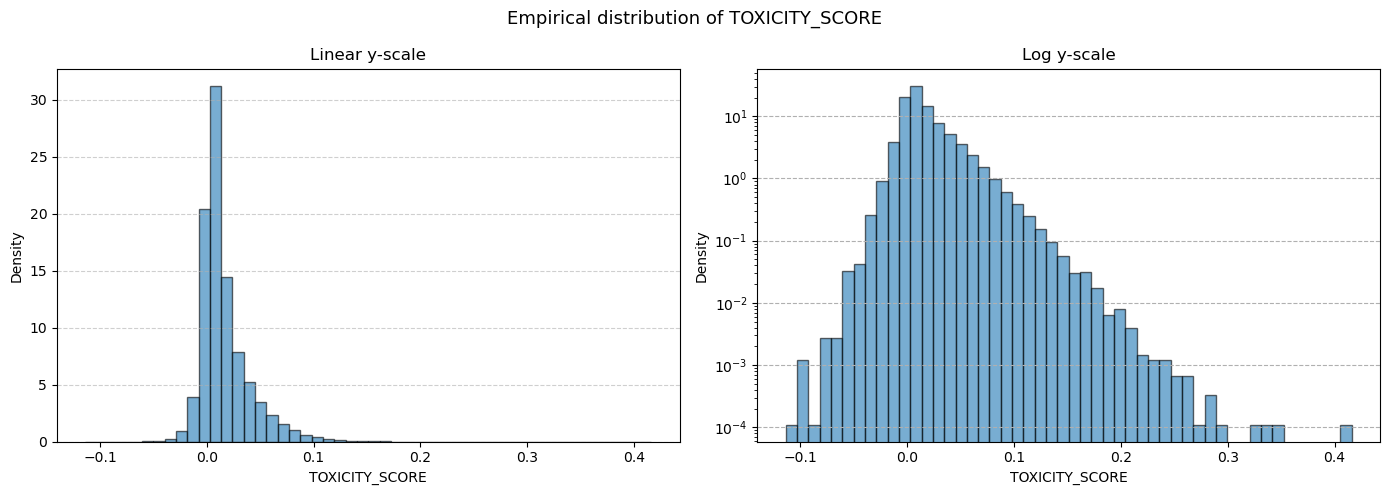

In [7]:
plot_empirical_distribution(interactions_df["TOXICITY_SCORE"], "TOXICITY_SCORE")

Although theoretically ranging from -1 to 1 by construction, we observe that `TOXICITY_SCORE` only take values between approx. -0.1 and 0.4. This is however not a problem because we later introduce multiple centering and scaling operations.

We now have a reliable, continuous measure of toxicity. But it's not necessarily easy to interpret it directly... We would like to accompany this continuous metric with a binary classification: "Is this toxicity score high? In other words, is this message toxic?"

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_CAT</code>: categorical metric that classifies posts as toxic (0) or toxic (1), after passing a threshold on <code>TOXICITY_SCORE</code>. 
</div>

For now, the threshod above which messages are flaggde as toxic is the quantile-75 of thetoxicity scores distribution. That is, **we mark as significantly toxic the top 25% messages with highest score**. While this is a reasonable and consistent approach, this threshold can be better set in the future and we will probably explore better ways to classify messages.

In [8]:
toxicity_bascule = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", toxicity_bascule)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= toxicity_bascule).astype(int)

75% quantile threshold: 0.02368686868687879


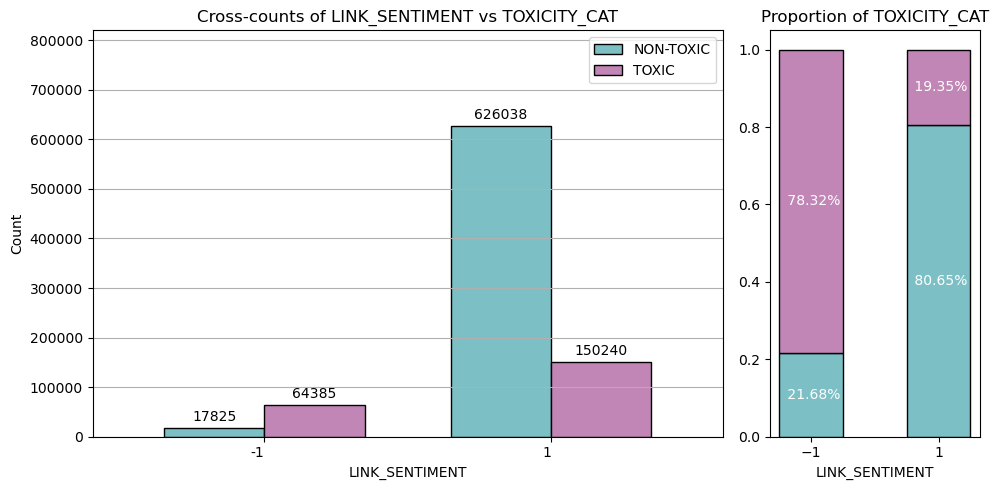

In [9]:
cross_count_SENTIMENT_TOXICITY(interactions_df)

At first, it appears that the majority of toxic messages are actualy labeled positive, which is not desirable as we explicited that, in our context, toxicity only comes with negativity. 

However, looking at the **proportions** of toxicity in each sentiment class (right barplot), we see that around 78% of negative messages are labeled toxic, while only 19% of positive messages were. Negative messages are much more likely to be toxic (which makes sense based on the properties we retained to define toxicity).

In the next cell, we enforce the rule that only messages with negative sentiment (`LINK_SENTIMENT` = −1) can be classified as toxic (`TOXICITY_CAT` = 1). This decision is based on a conceptual definition of toxicity as hostile, harmful, or abusive discourse, which fundamentally requires a negative emotional valence. Although positive/neutral-sentiment messages may sometimes contain high levels of features like swearing or anger, classifying them as toxic would introduce significant false positives that do not align with the standard understanding of online harassment or abuse.

**Remark**

The continuous `TOXICITY_SCORE` is preserved even for the links that are ultimately filtered out by the sentiment check. This score serves as a crucial linguistic feature intensity metric, quantifying the sheer presence of aggressive or low-quality language features (e.g., swearing, anger, simplicity) independent of the link's overall "true" sentiment. By keeping the raw score, we retain valuable information for later analysis, such as comparing the distribution of strong language features across both toxic (negative sentiment) and non-toxic (positive sentiment) messages, which can reveal linguistic patterns related to intense discourse beyond just negative intent.

In [10]:
interactions_df["TOXICITY_CAT"] = ((interactions_df["TOXICITY_CAT"] == 1) & (interactions_df["LINK_SENTIMENT"] == -1)).astype(int)

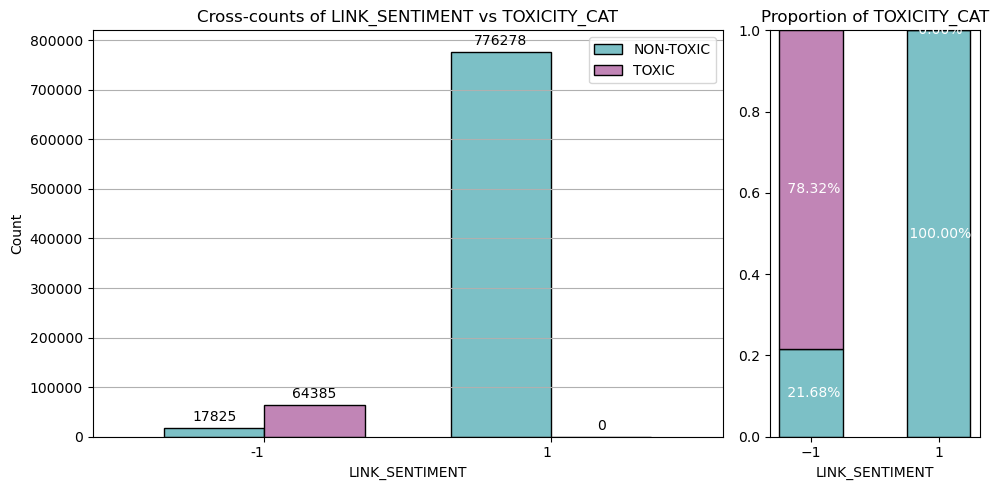

In [11]:
# Sanity check (to verify elimination of false positives)
cross_count_SENTIMENT_TOXICITY(interactions_df)

Let's see how much toxic posts we detected over the entire period. The following plot aggregates over all subreddits and averages monthly, but acts as a quick sanity check to see if the count stays coherent over time.

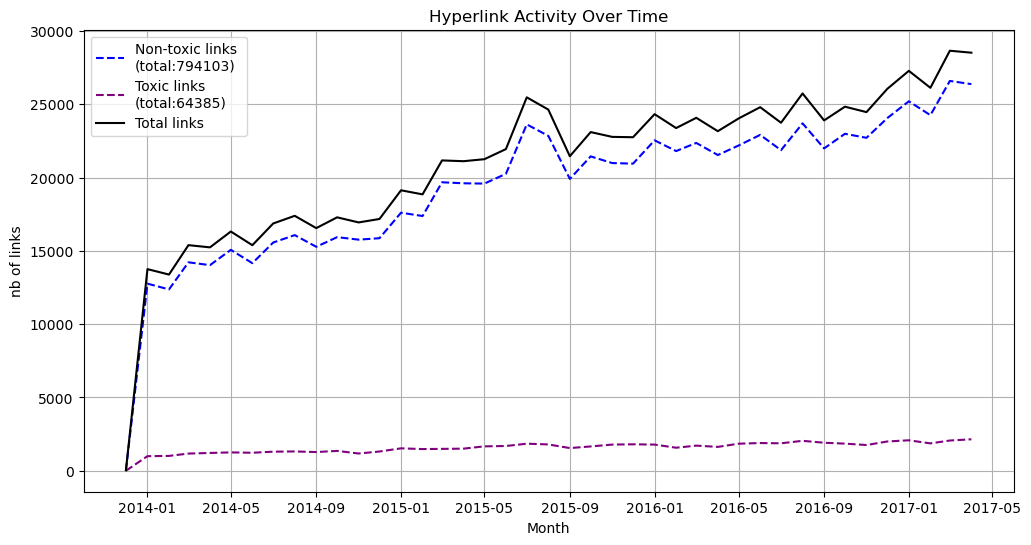

In [12]:
interactions_df["year_month"] = interactions_df["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

links_over_time_sent = (
    interactions_df.groupby(["year_month", "TOXICITY_CAT"])
    .size()
    .reset_index(name="n_links")
)

links_over_time_pivot = links_over_time_sent.pivot(
    index="year_month", columns="TOXICITY_CAT", values="n_links"
).fillna(0)

links_over_time_pivot["total"] = links_over_time_pivot.sum(axis=1)
toxicity_counts = interactions_df["TOXICITY_CAT"].value_counts()

plt.figure(figsize=(12, 6))
plt.plot(links_over_time_pivot.index, links_over_time_pivot[0], label=f"Non-toxic links \n(total:{toxicity_counts[0]})", color='blue', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot[1], label=f"Toxic links \n(total:{toxicity_counts[1]})", color='purple', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot["total"], label="Total links", color="black")

plt.title("Hyperlink Activity Over Time")
plt.xlabel("Month")
plt.ylabel("nb of links")
plt.legend()
plt.grid(True)
plt.show()

### 1.2.2 Supporting and Derived Metrics 

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**Count Metrics:**

(Following metrics can be restricted to a specified time window)
- `TOXICITY_COUNT`: Number of posts classified toxic during the time window.
- `NON_TOXICITY_COUNT`: Number of posts classified toxic during the time window.
- `TOTAL_COUNT`: Readability + word length + vocabulary richness.

These metrics also act as a foundation for the following rate-based metrics.`

</div>

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**Rate-Based Metrics:**

To quantify frequency and ratios of toxic behavior.

- `TOXICITY_RATE`: Proportion of toxic source messages in a time window, calculated as `TOXIC_COUNT` divided by `TOTAL_COUNT`. Range: 0–1.
- `TOXICITY_ODDS`: Alternative measure calculated as `TOXIC_COUNT` divided by `NON_TOXIC_COUNT`. Could be used to model odds and log-odds for logistic models in the following steps of the project.

</div>

In [13]:
# Implement these metrics

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Rollingly Normalized Score Metric:**

<code>TOXICITY_SCORE_ROLLZ</code>: continuous metric <code>TOXICITY_SCORE</code>, normalized on a lagging rolling window (that is, at each date it is centered on its rolling average and divided by its rolling std). No look-ahead bias is applied (the metric can be used for future prediction task just like the original score)For now, we keep the temporal window to 1 year.

The use of this last metric is to facilitate detecting **toxicity bursts**: when <code>TOXICITY_SCORE_ROLLZ</code> passes above a threshold (for example 2), it means that this post is more toxic by 2*std than the toxicity mean of all posts of last year. 
</div>

In [14]:
rolling_window = "365D" # The time window can be adjusted as needed

interactions_df["TOXICITY_SCORE_ROLLZ"] = (
    (interactions_df["TOXICITY_SCORE"] -
     interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].mean())
    / interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].std()
)

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**General Normalization Metrics:**

To contextualize toxicity scores within recent history (i.e., the considered time window).

- `BASE_TOXICTY_OFFSET`: Mean of `TOXICITY_SCORE` within the time window.
- `TOXICITY_STD`: Standard deviation of `TOXICITY_SCORE` within the time window.
- `TOXICITY_CONTEXT_ZSCORE`: Z-score of `TOXICITY_SCORE` within the time window.
</div>


In [ ]:
base_offset = compute_base_toxicity_offset(interactions_df, 'yearly')
tox_std = compute_toxicity_std(interactions_df, 'yearly')
context_zscore = compute_toxicity_context_zscore(interactions_df, 'yearly')

c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:110: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].mean()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:158: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].std()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:158: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].std()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\

,BASE_TOXICITY_OFFSET,TOXICITY_STD,TOXICITY_CONTEXT_ZSCORE
2013-12-31 00:00:00,0.009410,0.019562,NaN
2014-12-31 00:00:00,0.016029,0.022846,NaN
2015-12-31 00:00:00,0.016474,0.023332,NaN
2016-12-31 00:00:00,0.016527,0.023819,NaN
2017-12-31 00:00:00,0.016097,0.023829,NaN
0,NaN,NaN,-0.045794
1,NaN,NaN,-0.481001
2,NaN,NaN,0.493553
3,NaN,NaN,0.622692
4,NaN,NaN,0.037780



DataFrame shape: (858493, 3)
Columns: ['BASE_TOXICITY_OFFSET', 'TOXICITY_STD', 'TOXICITY_CONTEXT_ZSCORE']


<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**Directional Metrics:**

These metrics are subreddit-specific and will allow to explore community behaviors.

- `TOXICITY_OUT`: Toxic links sent by a subreddit (aggressor behavior)
- `TOXICITY_IN`: Toxic links received by a subreddit (victim/target behavior)
- `TOXICITY_BALANCE`: Net toxicity = `TOXICITY_OUT - TOXICITY_IN`
- `RECIPROCAL_TOXICITY`: Bidirectional toxic relationships between subreddit pairs which corresponds to the number of bidirectional edges in the toxic interaction graph.

</div>



In [17]:
# Implement these metrics

### 1.2.3 Potential Metrics to implement

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px;  display: inline-block; width: 90%; box-sizing: border-box;">
 
**Advanced Linguistic Metrics:**

To focus on **specific properties** of what was used to define toxicity. Could be useful and interesting when analysing the propagation of the negativity among subreddits.

- `PERSONAL_ATTACK_SCORE`: LIWC_You + LIWC_Negemo combinations.
- `RATIONAL_DISCOURSE_SCORE`: LIWC_CogMech + LIWC_Cause. 
- `COMPLEXITY_SCORE`: Readability + word length + vocabulary richness.

</div>

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**Temporal Metrics:**
- `TOXICITY_VELOCITY`: Rate of change in toxicity over time (Δtoxicity_rate / Δtime)
- `TOXICITY_ACCELERATION`: Second derivative (change in velocity)
- `TOXICITY_PERSISTENCE`: Duration of sustained toxic behavior (consecutive toxic periods)

</div>

## 1.3 Network Construction and Representation

1. Build temporal network snapshots (monthly/yearly windows as shorter windows seem unreasonable given the data)  
2. Build directed graphs for each time period
3. Compute node edge attributes: degrees, toxicity metrics, network centrality measures, eigenvector centrality
4. Store as adjacency lists or graph objects for analysis

### 1.3.1 Computing overall mean toxicity score

To get an overall idea of whether we can detect clusters of toxic subreddits, we compute the mean toxicity score of the interactions going out of each subreddit, and use the embeddings to map them.

In [ ]:
# === Compute mean toxicity for each source subreddit ===
mean_toxicity = (
    interactions_df.groupby("SOURCE_SUBREDDIT")["TOXICITY_SCORE"]
    .mean()
    .rename("mean_toxicity_score")
)

# === Quick sanity check ===
print(mean_toxicity.head())
print(f"\nTotal subreddits with data: {mean_toxicity.ne(0).sum()} / {len(mean_toxicity)}")

### 1.3.2 Mapping most active subreddits mean toxicity score

To obtain a readable and interpretable map (with not too many subreddits), we only keep active subreddits (the ones that have more than 20 outgoing interactions over the time period).
We use UMAP (Uniform Manifold Approximation and Projection) to reduce the dimensionality of the embeddings (300) to a plottable 2D map, to see the proximity between subreddits based on their embedding representations. UMAP is a nonlinear dimensionality reduction technique that preserves both local and global structure in the data, making it well-suited for visualizing complex high-dimensional relationships between subreddits in a 2D space.

In [ ]:
# Use utils function to filter active subreddits and get their embeddings
active_subs, filtered_embeddings = filter_active_subreddits(min_interactions=20)

# Reduce filtered embeddings from 3D to 2D
filtered_embeddings_2d = reduce_embeddings_2d(filtered_embeddings)

# Merge mean toxicity data
embeddings_with_toxicity = filtered_embeddings_2d.merge(
    mean_toxicity, left_on="SUBREDDIT", right_on="SOURCE_SUBREDDIT", right_index=True, how="left"
).fillna(0)

# === Plot ===
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=embeddings_with_toxicity,
    x="x", y="y",
    hue="mean_toxicity_score",
    palette="coolwarm",   
    s=25,
    alpha=0.8
)
plt.title("Subreddit Map (UMAP) - Subreddits with >20 Interactions")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Mean Toxicity Score", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

We can already see that some areas have a higher proportion of subreddits with a moderately high mean toxicity score. 
This observation is very broad since it only considers the mean toxicity over the whole period (2,5 years): communities should be easier to observe over a smaller time period, if selected correctly.

### 1.3.3 Monthly evolution of toxicity score

We check whether we can decompose the data into monthly time series by taking advantage of the 'TIMESTAMP' column, still with the most active subreddits, and plot them using an animated UMAP. 
We compute the monthly mean outgoing toxicity score of each subreddit to see their evolution with time.

In [ ]:
ani_monthly = animate_evolution(active_subs, filtered_embeddings, freq='M')
HTML(ani_monthly.to_jshtml())

This animation shows fluctuating toxicity scores for most subreddits, but also clusters who keep mostly toxic interactions throughout the whole time period (such as at the bottom left of the main island).

### 1.3.4 Weekly evolution of toxicity score

To later  be able to investigate cascades of toxicity with more precision, we try visualizing weekly evolution of toxicity scores

In [ ]:
ani_weekly = animate_evolution(active_subs, filtered_embeddings, freq='W')
HTML(ani_weekly.to_jshtml())

The result is too heavy to be displayed entirely but shows that we are able to study weekly fluctuations of toxicity of subreddits within a certain time window (to be later determined for cascade analysis).

---
# Phase 2: Outbreak Detection and Analysis (started, to finish after P2)

## 2.1 Community Exploration and Structure Analysis
- Detect subreddit clusters (who interacts with whom?)
- Characterize each community's baseline behavior
- Track community changes over time

### 2.1.1 Using the Louvain algorithm

The Louvain algorithm is a community detection method that groups nodes in a network into clusters (communities) by maximizing modularity, a measure of how densely connected nodes are within communities compared to between them. In our case, we apply the Louvain algorithm to the toxic interaction graph, where nodes represent subreddits and weighted edges represent the number of toxic interactions between them. This allows us to identify clusters of subreddits that frequently exchange toxic messages, revealing potential toxic communities.

In [ ]:
# Only select toxic interactions to build the graph to detect toxic communities
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1]  # keep only toxic interactions

# Find Louvain communities from toxic interactions and their number of interactions
community_df, toxic_interactions = louvain_communities(toxic_df)

# We consider communities with more than 30% toxic interactions as toxic
toxicity_threshold = 0.3

# Find toxic communities
community_df = get_toxic_communities(community_df, toxicity_threshold)

# Plot the biggest toxic community network
plot_biggest_toxic_community_network(community_df, toxic_interactions)

We observe that the Louvain algorithm mostly finds very small communities (1 or 2 subreddits). 
This is due to the fact that when using the full time period as we did here, toxic interactions are sparse and scattered across time, leading the Louvain algorithm to detect many small, isolated communities. By focusing on a shorter, well-chosen period where toxicity peaks (to be determined later), interactions are denser and more connected, making it easier to identify larger, more cohesive toxic communities.

## 2.2 Outbreak identification and Characterization
- **Detect outbreaks**: When toxicity suddenly spikes
- **Find origins (Patient-0)**: Which subreddit started it?
- **Measure impact**: How big did the outbreak get?


### 2.2.1 Data Focusing tool

In order to identify the patient 0, we first construct a tool capable of focusing on a time window and on links which contain a specific keyword. This allows us to dig into a more relevant part of the data, and therefore identify more easily trends in a given context. 

We highlight that this method is meant to help faster identification of trends, and that a more rigorous causal analysis will be conducted later on. This is important as this tool may focus too much on parts of the data, and thus eliminate precursors without eliminating their effect. In instance, the actual patient zero subreddit or community might not contain the chosen given in its name, leaving the possibility of having it as a precursor behind. The possibility of having the keyword in a subreddit name with no link is also possible (see example with 'nba', we get 'greeNBAypackers' as a related subreddit).

In [20]:
# Subreddit keyword to focus on
KEYWORD = "nba"

# Time Window to consider
# TIME_WINDOW = [date(2016, 6, 1), date(2017, 2, 1)] # TRUMP
TIME_WINDOW = [date(2015, 6, 1), date(2015, 8, 1)] # NBA

# Extract focused dadaframe
focused_df = extract_focused_df(interactions_df, KEYWORD, TIME_WINDOW)
focused_df.head(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE,LINK_SENTIMENT_ADJUST,TOXICITY_SCORE,TOXICITY_CAT,year_month,TOXICITY_SCORE_ROLLZ
293374,bestofrabsho,nba,37kkwhs,2015-06-01 06:52:48,1,46.0,41.0,0.760870,0.000000,0.217391,...,0.0,0.000000,0.0,0.0,title,0.00,0.010943,0,2015-06-01,-0.229211
293472,sneakers,nbamarketplace,383eris,2015-06-01 09:53:24,1,84.0,73.0,0.785714,0.000000,0.297619,...,0.0,0.000000,0.0,0.0,title,0.00,0.024784,0,2015-06-01,0.371469
293914,retiredusername,nba,38l1n6s,2015-06-01 21:03:45,1,34.0,31.0,0.794118,0.000000,0.147059,...,0.0,0.000000,0.0,0.0,title,0.00,0.005051,0,2015-06-01,-0.485011
294707,chibears,greenbaypackers,38bikys,2015-06-02 21:28:28,1,7001.0,6553.0,0.611341,0.123982,0.086273,...,0.0,0.000991,0.0,0.0,body,0.00,-0.005694,0,2015-06-01,-0.951057
294759,badeconomics,nba,38bxeis,2015-06-02 23:24:27,1,41.0,36.0,0.804878,0.000000,0.170732,...,0.0,0.000000,0.0,0.0,title,0.00,0.008658,0,2015-06-01,-0.328522
295010,nbacirclejerk,nbastreams,38e048s,2015-06-03 10:26:55,1,36.0,29.0,0.722222,0.000000,0.361111,...,0.0,0.000000,0.0,0.0,title,0.00,0.014731,0,2015-06-01,-0.065217
295354,seahawks,greenbaypackers,38fwkts,2015-06-03 17:47:04,1,4276.0,4117.0,0.654584,0.098223,0.047942,...,0.0,0.000000,0.0,0.0,body,0.00,-0.004901,0,2015-06-01,-0.916776
295458,subredditdrama,nba,38gw77,2015-06-03 21:00:00,-1,106.0,90.0,0.811321,0.000000,0.056604,...,0.0,0.000000,0.0,0.0,title,0.25,0.047456,1,2015-06-01,1.354760
295904,warriors,nba,38k6hc,2015-06-04 13:28:40,-1,921.0,798.0,0.741585,0.017372,0.041260,...,0.0,0.006289,0.0,0.0,body,0.25,0.026492,1,2015-06-01,0.445309
296497,nbacirclejerk,clevelandcavs,38okdos,2015-06-05 09:38:20,1,17.0,17.0,0.823529,0.000000,0.823529,...,0.0,0.000000,0.0,0.0,title,0.00,0.000000,0,2015-06-01,-0.704116


In this example we focus on the NBA keyword and over the course of two months from June 2015 to August 2015. For further information about how the extract_focused_df() function works, please refer to the associated 'identify_patient_zero_module.py' file. Note that the focused_df preserves the order of the given dataframe in entry, time in our case.

### 2.2.2 Analysis of specific subreddits interactions over a given time period
#### Number of daily interactions across each subreddit
We start by conducting a temporal analysis of all interactions, as source or as target. This allows us to identify interaction outbreaks, which will be further analyzed to see if they are positive, negative and/or toxic events.

There are 111 different subreddits acting as source.
There are 61 different subreddits acting as target.


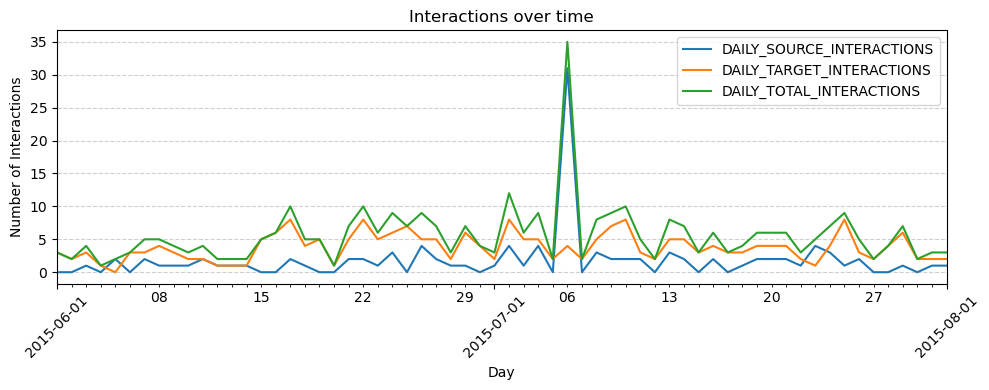

In [21]:
print("There are", len(focused_df["SOURCE_SUBREDDIT"].unique()), "different subreddits acting as source.")
print("There are", len(focused_df["TARGET_SUBREDDIT"].unique()), "different subreddits acting as target.")

# Count the number of daily interactions across all considered subreddits
daily_interaction_df = construct_daily_interaction_df(focused_df, KEYWORD, TIME_WINDOW)

# Plot
fig, ax = plt.subplots(figsize=(10,4))

daily_interaction_df[["DAILY_SOURCE_INTERACTIONS",
                      "DAILY_TARGET_INTERACTIONS",
                      "DAILY_TOTAL_INTERACTIONS"]].plot(ax=ax)

# ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Interactions over time")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Interactions")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

We can see that a clear outbreak appears at the beginning of July 2015. We can also see that overall there are more targeted subreddits than source (a smaller amount of subreddits target more other subreddits). But during the outbreak, the number of source subreddits explodes, indicating a lot more different subreddits linked to the same (small) amount of target subreddits. This could be a toxic wave coming from various different communities towards a particular subreddit.

#### Number of interactions (as source and target) for each subreddit 

To further analyze which subreddits are potential victims and prosecutors, we show the amount of interactions (as source and as target) for the 8 most interactive subreddits.

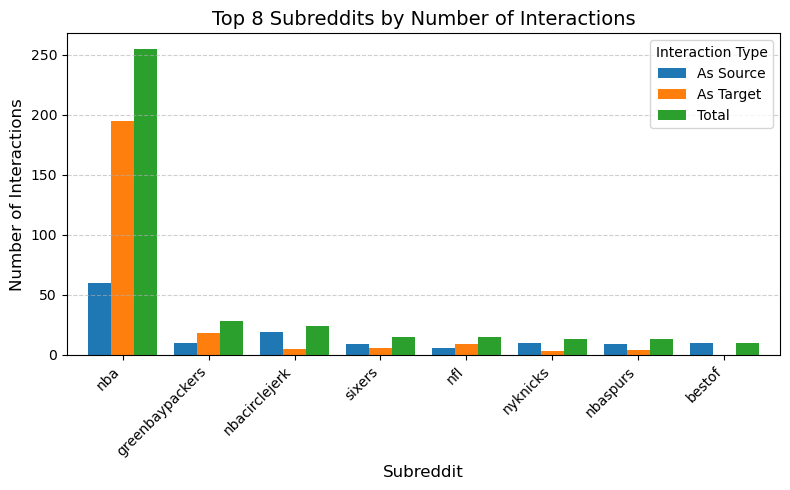

In [26]:
# Count the number of interaction as source and as target for each subreddit
sr_interaction_count_df = construct_interaction_count_df(focused_df)

# Choose the number of subreddits to plot
NB_TO_PLOT = 8

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sr_interaction_count_df.head(NB_TO_PLOT).plot(
    x="SUBREDDIT",
    y=["SOURCE_INTERACTIONS", "TARGET_INTERACTIONS", "TOTAL_INTERACTIONS"],
    kind="bar",
    width=0.8,
    ax=ax
)

ax.set_title("Top " + str(NB_TO_PLOT) + " Subreddits by Number of Interactions", fontsize=14)
ax.set_xlabel("Subreddit", fontsize=12)
ax.set_ylabel("Number of Interactions", fontsize=12)
ax.set_xticklabels(sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"], rotation=45, ha="right")
ax.legend(["As Source", "As Target", "Total"], title="Interaction Type")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

A clear trend of links towards the 'nba' subreddit shows up, and some others like the 'nbacirclejerk' appears as one of the most targeting subreddit. Although, the balance between subreddits is not equitable and therefore if any toxic outbreak were to be happening, this would mean many attackers are implied rather than a specific subreddit. This makes the analysis more complicated, as we have to analyze the evolution interactions for each small subreddit separately. This is because we need to see if it is indeed a change in their behaviour or a recurrent interaction between the target and the source. 

#### Number of negative daily interactions across each subreddit 

We now study the interactions themselves to see if they are negative and/or toxic based on as many criteria as wanted. Here, we take:
- 'LINK_SENTIMENT' == -1,
- 'COMPOUND_SENTIMENT_CALCULATED_BY_VADER' <= -0.5,
- 'NEGATIVE_SENTIMENT_CALCULATED_BY_VADER' >= 0.1

These are very non-strict thresholds, for the sake of the example.  

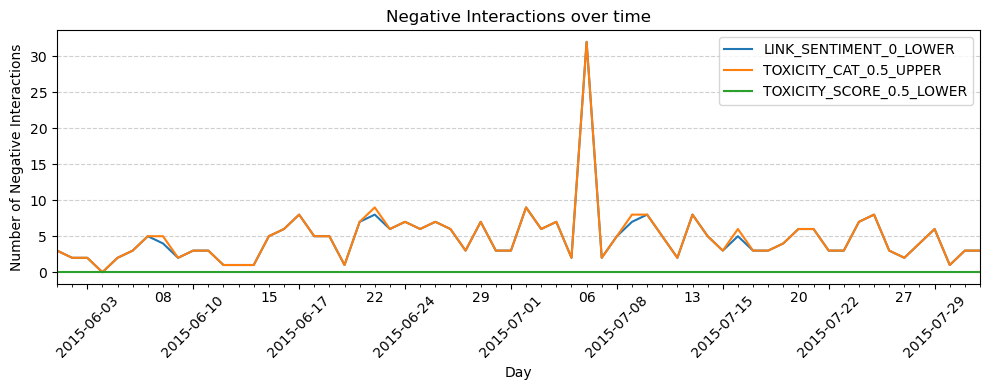

,LINK_SENTIMENT_0_LOWER,TOXICITY_CAT_0.5_UPPER,TOXICITY_SCORE_0.5_LOWER
DAY,,,
2015-06-01,3,3,0
2015-06-02,2,2,0
2015-06-03,2,2,0
2015-06-04,0,0,0
2015-06-05,2,2,0
...,...,...,...
2015-07-28,4,4,0
2015-07-29,6,6,0
2015-07-30,1,1,0


In [24]:
# Count the number of negative daily interactions across all considered subreddits
CRITERION = ["LINK_SENTIMENT",
             "TOXICITY_CAT",
             "TOXICITY_SCORE"
             #"TOXICITY_SCORE_ROLLZ"
             ]
THRESHOLDS = [0,
              0.5,
              0.5
              #0.10
              ]
UPPER = [False,
         True,
         False
         # False
        ]
daily_neg_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="DAY")

# Plot
fig, ax = plt.subplots(figsize=(10,4))

daily_neg_interaction_df.plot(ax=ax)

ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Negative Interactions over time")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Negative Interactions")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Show dataframe for further investigation
daily_neg_interaction_df

It appears that during the outbreak, 28 of the 35 interactions have a negative sentiment calculated by VADER above 0.1, but only 1 interaction has a negative link_sentiment. In this example, we would tend to say this is not a major negative outbreak, and that these results are non-conclusive. This could be an outbreak with regular amount of toxicity, or simply a non-negative outbreak. Note again that this should and will be further analyzed to quantify the regular amount of toxicity and that relevance of criteria should be investigated (causal analysis in P3).

#### Number of negative aggregated interactions for each subreddit

Finally, we add a plot showing the number of negative interactions for each subreddit which allow us to highlight which subreddit is associated with negative links.

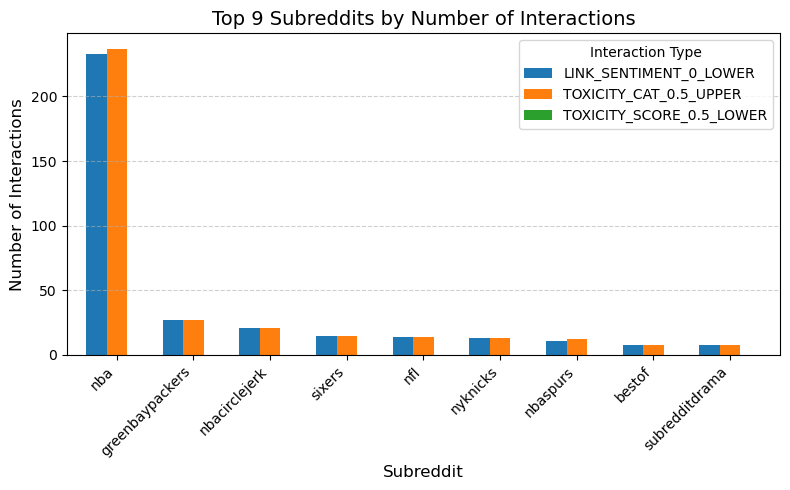

In [25]:
# Count the number of negative interactions for each considered subreddit

# Compute negative interactions as source
sr_neg_source_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="SOURCE_SUBREDDIT")
# Compute negative interactions as target
sr_neg_target_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="TARGET_SUBREDDIT")
# Add interactions and sort them by total
sr_neg_interaction_df = smart_df_add(sr_neg_source_interaction_df, sr_neg_target_interaction_df)
sr_neg_interaction_df["TOTAL_NEGATIVE_INTERACTIONS"] = sr_neg_interaction_df.sum(axis=1)
sr_neg_interaction_df = sr_neg_interaction_df.sort_values(by="TOTAL_NEGATIVE_INTERACTIONS", ascending=False)

# Choose the number of subreddits to plot
NB_TO_PLOT = 9

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sr_neg_interaction_df.head(NB_TO_PLOT).plot(
    y=sr_neg_interaction_df.columns[:-1],
    kind="bar",
    width=0.8,
    ax=ax
)

ax.set_title("Top " + str(NB_TO_PLOT) + " Subreddits by Number of Interactions", fontsize=14)
ax.set_xlabel("Subreddit", fontsize=12)
ax.set_ylabel("Number of Interactions", fontsize=12)
ax.set_xticklabels(sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"], rotation=45, ha="right")
ax.legend(sr_neg_interaction_df.columns, title="Interaction Type")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Again, the 'nba' subreddit stands out which makes sense as it was the most interactive during this period. We can see that the total amount of negative interactions goes up to roughly 70 over 250 total interactions based on the negative VADER criterion, and only up to 20 using link_sentiment. As explained above, habitual toxic interaction ratio and relevance of each criterion should be further investigated and motivated. 

We therefore cannot assess if it was a negative outbreak for the 'nba' subreddit or not, based on the current results. This is still a good example of how we aim to find potential patient-0, as a first step in the whole process. We emphasize the complexity of this task which still needs deeper analysis (see causal analysis next), and we are aware that a more detailed exploration is needed (pursued in P3).

### 2.2.3 Causal Analysis (P3)

This allows us to perform a more trustful study based on the prior beliefs obtained in the previous section. This includes assessing relevance of criteria and thresholds and global toxic trends of each subreddit in this context among others.

---
# Phase 3: Propagation and Diffusion Analysis (after P2)

## 3.1 Cascade Tracing and Flow Dynamics
- **Find chains**: A→B→C toxic spreading patterns
- **Analyze mutations**: How toxicity changes as it spreads
- **Model contagion**: What makes toxicity spread?

## 3.2 Immunity and Containment Effects
- **Positive alliances**: Do friendly connections protect communities?
- **Resistance factors**: What makes communities immune?

---

# Phase 4: Lifecycle and Evolution Study (after P2)


## 4.1 Detection of Cycles and Key Events
- **Periodicity**: Does toxicity follow seasonal patterns? (Fourier analysis)
- **Event correlation**: Do real-world events trigger spikes?

## 4.2 Evolutionary tracking over time
- **Classify trajectories**: How do toxic communities evolve?: Is there a gradual radicalization? Or sudden outbreaks? Do we observe chronic toxicity?
- **Early warning**: Try to predict which communities will become toxic

---
# Phase 5: Validation and Synthesis of Results (Conclusion)



## 5.1 Create Visualizations
We could create various visualizations to effectively communicate our findings. Examples such as :  Animated networks showing toxicity spread, Epidemic curves (like flu charts), etc.


## 5.2 Final Interpretation and Conclusions